In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [13]:
dataset = pd.read_csv("weather_classification_data.csv")
dataset.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


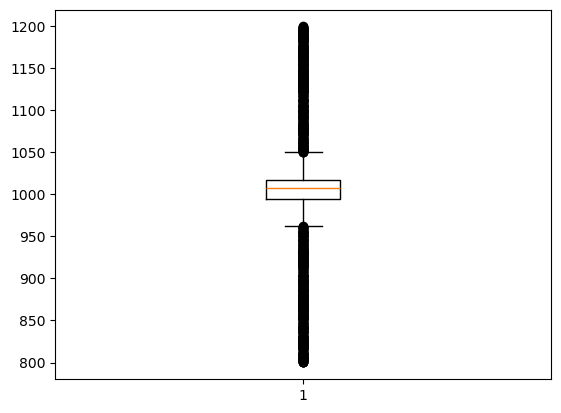

In [14]:
plt.boxplot(x="Atmospheric Pressure",data=dataset)
plt.show()

In [15]:
q1 = dataset["Atmospheric Pressure"].quantile(0.25)
q3 = dataset["Atmospheric Pressure"].quantile(0.75)
iqr = q3 - q1
q1,q3,iqr

(994.8, 1016.7725, 21.972500000000082)

In [16]:
max_range = q3 + (iqr*1.5)
min_range = q1 - (iqr*1.5)
max_range , min_range

(1049.7312500000003, 961.8412499999998)

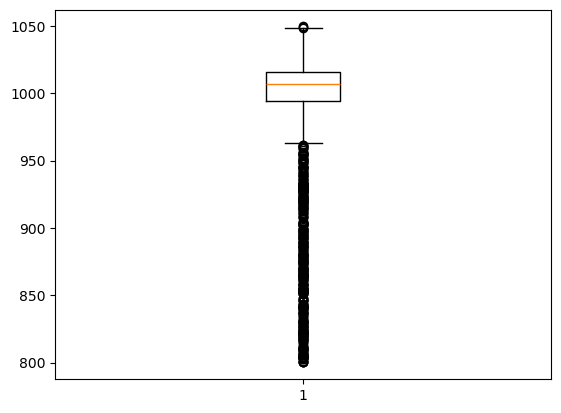

In [17]:
new_dataset=dataset[dataset["Atmospheric Pressure"]<=max_range]
plt.boxplot(x="Atmospheric Pressure", data=new_dataset)
plt.show()

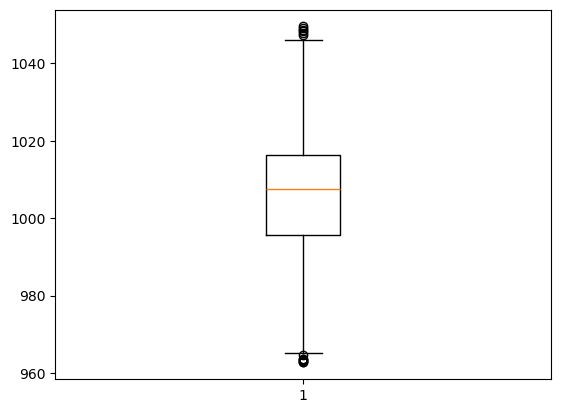

In [18]:
Dataset=new_dataset[new_dataset["Atmospheric Pressure"]>=min_range]
plt.boxplot(x="Atmospheric Pressure",data=Dataset)
plt.show()

In [19]:
from sklearn.preprocessing import FunctionTransformer

In [20]:
ft = FunctionTransformer(func = np.log1p)
ft.fit(Dataset[["Atmospheric Pressure"]])


FunctionTransformer(func=<ufunc 'log1p'>)

In [23]:
Dataset["Atmospheric Pressure_ft"]= ft.transform(Dataset[["Atmospheric Pressure"]])
Dataset

C:\Users\Suchana\AppData\Local\Temp\ipykernel_10004\965734683.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Dataset["Atmospheric Pressure_ft"]= ft.transform(Dataset[["Atmospheric Pressure"]])


,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type,Atmospheric Pressure_ft
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy,6.919506
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy,6.920109
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny,6.927283
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny,6.934641
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy,6.899390
...,...,...,...,...,...,...,...,...,...,...,...,...
13194,29.0,62,13.0,17.0,overcast,1002.81,2,Spring,5.0,coastal,Cloudy,6.911558
13195,10.0,74,14.5,71.0,overcast,1003.15,1,Summer,1.0,mountain,Rainy,6.911897
13197,30.0,77,5.5,28.0,overcast,1012.69,3,Autumn,9.0,coastal,Cloudy,6.921352
13198,3.0,76,10.0,94.0,overcast,984.27,0,Winter,2.0,inland,Snowy,6.892916


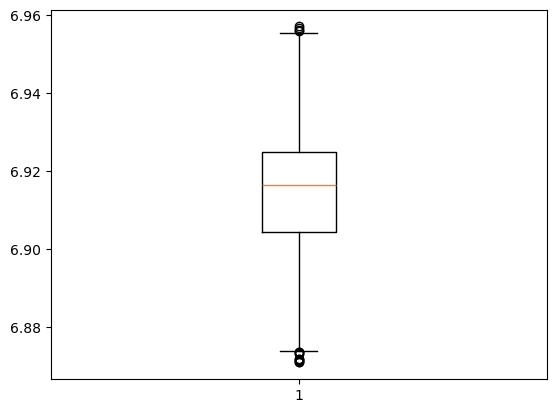

In [24]:
plt.boxplot(x="Atmospheric Pressure_ft",data=Dataset)
plt.show()